# 04 · Peak Detection

How to find the peaks in a spectrum automatically and measure their center, FWHM and height.

1. Detect peaks in a clean spectrum
2. Set the threshold from the noise
3. Check detections against the true peaks
4. Close peaks merge into one
5. The second derivative finds hidden peaks

Code: `src/spectro/peaks.py`.

## Setup

In [1]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

from spectro import (
    Peak,
    detect_peaks,
    detect_peaks_derivative,
    estimate_noise,
    make_spectrum,
    match_peaks,
    plot_spectrum,
    remove_baseline,
    smooth,
)

peaks = [
    Peak(center=3350, fwhm=300, height=0.6, shape="gaussian"),  # O–H
    Peak(center=2950, fwhm=40, height=0.4),  # C–H
    Peak(center=2870, fwhm=30, height=0.3),  # C–H
    Peak(center=1715, fwhm=25, height=0.9),  # C=O
    Peak(center=1100, fwhm=50, height=0.5, shape="lorentzian"),  # C–O
]
clean, true_peaks = make_spectrum(peaks)
raw, _ = make_spectrum(peaks, noise=0.01, baseline=(0.05, 0.1, -0.05), seed=0)

## 1. Detect Peaks in a Clean Spectrum

`detect_peaks` returns a table with the same columns as the true peak table: center, FWHM and height, plus the prominence (how far the peak rises above its surroundings). The isolated peaks come back almost exactly. The C–H peak at 2870 cm⁻¹ sits on the shoulder of the one at 2950 cm⁻¹, so its width is measured from the shoulder and comes out too narrow.

In [2]:
found = detect_peaks(clean)
found.round(2)

,center,fwhm,height,prominence
0,1100.00,49.71,0.50,0.50
1,1715.00,25.15,0.90,0.90
2,2870.13,25.79,0.31,0.25
3,2949.99,37.92,0.41,0.37
4,3349.91,300.24,0.60,0.60


In [3]:
true_peaks.round(2)

,shape,center,fwhm,height,area
0,lorentzian,1100,50,0.5,39.27
1,pseudo_voigt,1715,25,0.9,29.65
2,pseudo_voigt,2870,30,0.3,11.86
3,pseudo_voigt,2950,40,0.4,21.08
4,gaussian,3350,300,0.6,191.60


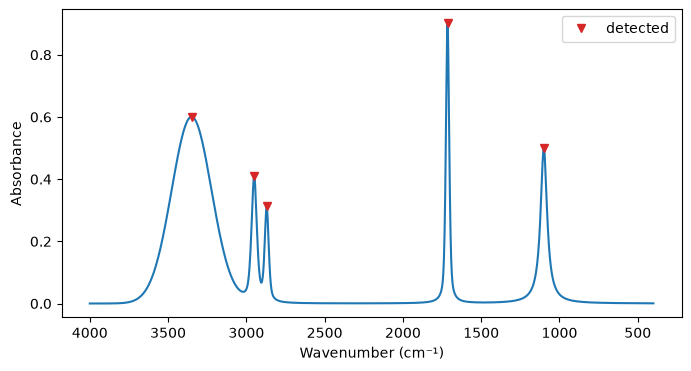

In [4]:
ax = plot_spectrum(clean)
ax.plot(found["center"], found["height"], "v", color="tab:red", label="detected")
ax.legend();

## 2. Set the Threshold from the Noise

A peak is kept only if its prominence is above a threshold, by default 5 × the noise. `estimate_noise` measures the noise from point-to-point changes, which smoothing removes, so estimate it *before* smoothing. Detecting on the unsmoothed spectrum (left) picks up noise bumps and splits the broad O–H band; smoothing first with the threshold from the raw noise (right) finds only the real peaks.

In [5]:
corrected = remove_baseline(raw)
noise = estimate_noise(corrected)
print(f"estimated noise: {noise:.4f} (true 0.01)")

unsmoothed = detect_peaks(corrected)
smoothed = smooth(corrected)
detected = detect_peaks(smoothed, prominence=5 * noise)
print(f"unsmoothed: {len(unsmoothed)} peaks, smoothed: {len(detected)} peaks")

estimated noise: 0.0098 (true 0.01)
unsmoothed: 10 peaks, smoothed: 5 peaks


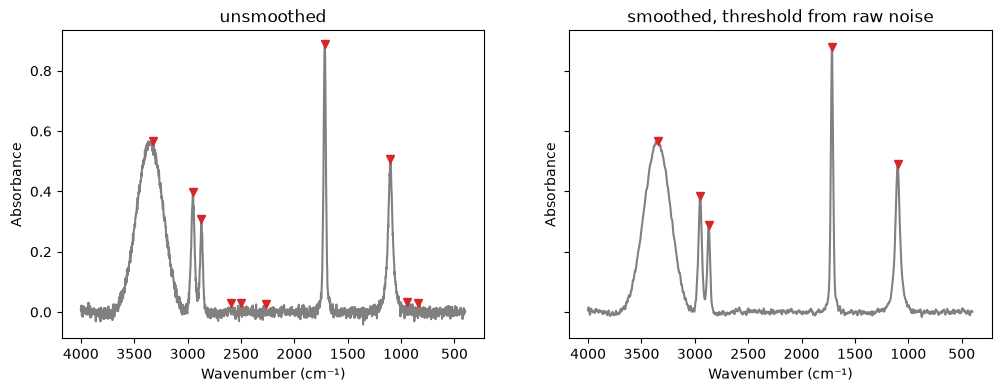

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, spectrum, table, title in [
    (left, corrected, unsmoothed, "unsmoothed"),
    (right, smoothed, detected, "smoothed, threshold from raw noise"),
]:
    plot_spectrum(spectrum, ax=ax, color="gray")
    ax.plot(table["center"], table["height"], "v", color="tab:red")
    ax.set_title(title)

## 3. Check Detections Against the True Peaks

`match_peaks` pairs each detected peak with the nearest true peak within `tolerance` cm⁻¹. Rows with NaN on one side are missed or false peaks. The narrow peaks land within about a wavenumber of the truth; the broad O–H band has a flat top, so noise moves its detected center by several wavenumbers, and a wider tolerance is needed for it.

In [7]:
matched = match_peaks(detected, true_peaks, tolerance=40)
matched["center_error"] = matched["center_found"] - matched["center_true"]
matched["fwhm_error"] = matched["fwhm_found"] - matched["fwhm_true"]
matched[
    [
        "center_true",
        "center_found",
        "center_error",
        "fwhm_true",
        "fwhm_found",
        "fwhm_error",
    ]
].round(2)

,center_true,center_found,center_error,fwhm_true,fwhm_found,fwhm_error
0,1100,1100.11,0.11,50,49.48,-0.52
1,1715,1715.23,0.23,25,26.03,1.03
2,2870,2870.04,0.04,30,26.47,-3.53
3,2950,2949.54,-0.46,40,37.44,-2.56
4,3350,3341.99,-8.01,300,294.83,-5.17


## 4. Close Peaks Merge into One

Two equal peaks still show a dip when they are one FWHM apart, but closer than about three-quarters of a FWHM the dip disappears and detection sees a single, wider peak. With noise the limit comes sooner, because a shallow dip falls below the threshold. This is the limit of looking for maxima. The second derivative (part 5) goes a little further; fully separating overlapping peaks is the job of deconvolution (step 6).

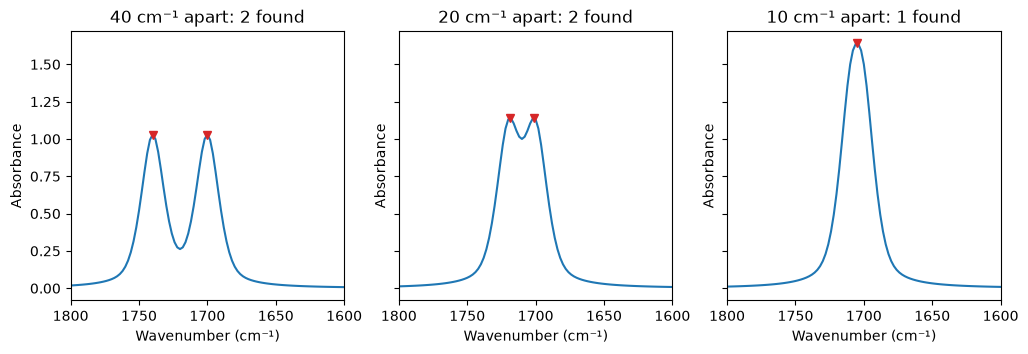

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, separation in zip(axes, [40, 20, 10], strict=True):
    pair, _ = make_spectrum([Peak(1700, 20, 1.0), Peak(1700 + separation, 20, 1.0)])
    pair_peaks = detect_peaks(pair)
    plot_spectrum(pair, ax=ax)
    ax.plot(pair_peaks["center"], pair_peaks["height"], "v", color="tab:red")
    ax.set_xlim(1800, 1600)
    ax.set_title(f"{separation} cm⁻¹ apart: {len(pair_peaks)} found")

## 5. The Second Derivative Finds Hidden Peaks

Every band makes a sharp dip in the second derivative, narrower than the band itself, even when it makes no maximum in the spectrum. `detect_peaks_derivative` finds those dips. It is the usual way to locate overlapping IR bands before fitting them. Below, a shoulder (left) and a pair 12 cm⁻¹ apart (right) each give one maximum but two dips. The plots show the *negated* second derivative, so the dips point up.

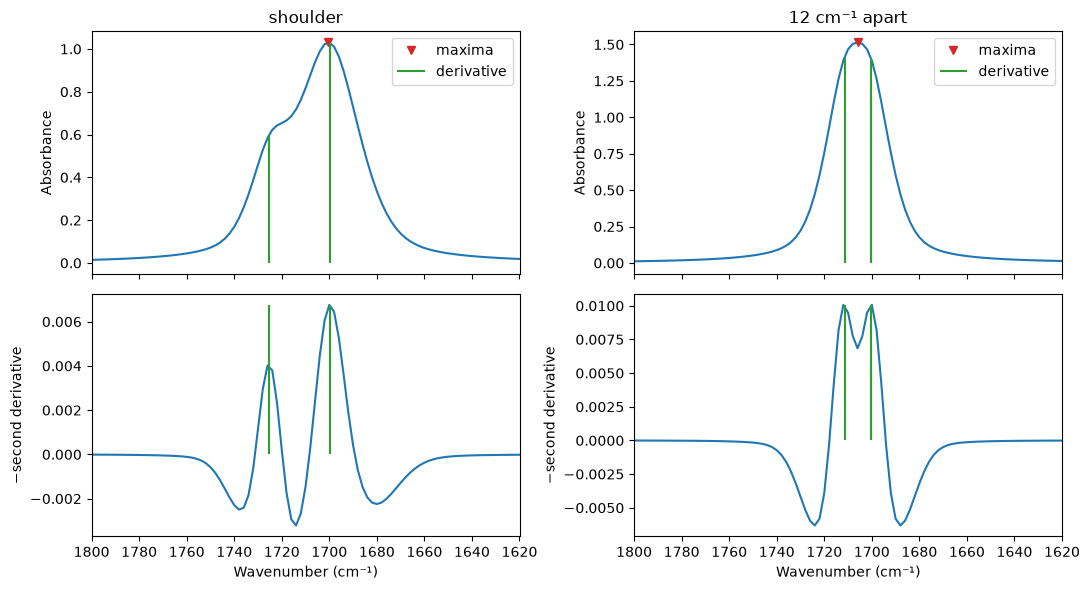

In [9]:
cases = [
    ("shoulder", [Peak(1700, 30, 1.0), Peak(1725, 20, 0.4)]),
    ("12 cm⁻¹ apart", [Peak(1700, 20, 1.0), Peak(1712, 20, 1.0)]),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for (title, case), (top, bottom) in zip(cases, axes.T, strict=True):
    spectrum, _ = make_spectrum(case)
    maxima = detect_peaks(spectrum)
    dips = detect_peaks_derivative(spectrum)

    plot_spectrum(spectrum, ax=top)
    top.plot(maxima["center"], maxima["height"], "v", color="tab:red", label="maxima")
    top.vlines(dips["center"], 0, dips["height"], color="tab:green", label="derivative")
    top.set_title(title)
    top.set_xlabel("")
    top.legend()

    curvature = -savgol_filter(spectrum.y, 11, 4, deriv=2, delta=2.0)
    bottom.plot(spectrum.x, curvature)
    bottom.vlines(dips["center"], 0, curvature.max(), color="tab:green")
    bottom.set_ylabel("−second derivative")
    bottom.set_xlabel("Wavenumber (cm⁻¹)")
    bottom.set_xlim(1800, 1620)
fig.tight_layout()

The cost is noise: differentiating amplifies it, so the threshold has to be higher, and the depth of a band's dip falls with its width squared. At low noise the derivative finds every band except the broad O–H; at the noise level used in parts 2–3 it misses most of them, while smoothing and looking for maxima still finds all five. Use the derivative on good-quality spectra, and maxima when the data are noisy.

In [10]:
for noise in [0.002, 0.01]:
    raw_n, _ = make_spectrum(peaks, noise=noise, baseline=(0.05, 0.1, -0.05), seed=0)
    corrected_n = remove_baseline(raw_n)
    noise_n = estimate_noise(corrected_n)
    by_maxima = detect_peaks(smooth(corrected_n), prominence=5 * noise_n)
    by_derivative = detect_peaks_derivative(corrected_n)
    print(f"noise {noise}: maxima {len(by_maxima)}, derivative {len(by_derivative)}")

noise 0.002: maxima 5, derivative 4
noise 0.01: maxima 5, derivative 1
